# Practice task — Task 6: Where does green energy innovation happen?

*Made-up extra task in the style of the term paper, using the same three data files.*

The applicant file links every applicant to one or more **regions** (`reg_code`, OECD small regions, e.g. `DE212` =
Munich, `US06085` = Santa Clara County). When an applicant is linked to several regions, `reg_share` splits the
applicant between them, so the `reg_share`s of one applicant on one patent add up to 1.

1. Count green energy patents (Y02E, priority years 2000–2019) per region with **double fractional counting**: each
   applicant–region row gets the weight `app_share × reg_share`. Check that the weights of a patent add up to 1.
2. Which **10 regions** had the most green energy patents in 2005–2009 and in 2015–2019? Show them in a table and a
   figure. Label each region with its country and its most common applicant city.
3. Is green energy innovation **more geographically concentrated** than patenting in general? Compare the share of
   the top 10 regions and a Herfindahl index (HHI) for green and all patents in each five-year period.
4. Did the **slump** (Task 2) hit the leading regions equally? For the top 10 regions in 2010–2014, compute the change
   in green patents to 2015–2019 and compare with the change for all green patents.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

IPC_FILE = "data/202608_EPO_IPC.txt"
CPC_FILE = "data/202608_CPC_Classes.txt"
APP_FILE = "data/202608_EPO_App_reg.txt"

sample_start = 2000
sample_end = 2019

# Five-year periods, made with pd.cut so no period is typed in by hand
period_edges = list(range(sample_start - 1, sample_end + 1, 5))
period_labels = [f"{e + 1}–{e + 5}" for e in period_edges[:-1]]

## Read the data

The readers follow Task 1: each file is read once, and only the rows of patents in the sample are kept. Unlike Task 1,
we now **keep the region columns** (`reg_code`, `city`, `reg_share`) and `person_id`, because an applicant linked to
several regions appears on one row per region.

In [2]:
def read_sample(path, first_year, last_year):
    """One row per EPO application with priority year in [first_year, last_year]."""
    ipc = pd.read_csv(path, sep="|", usecols=["appln_id", "prio_year"])
    in_period = ipc["prio_year"].between(first_year, last_year)
    return ipc.loc[in_period].drop_duplicates("appln_id").reset_index(drop=True)


def read_green_ids(path, sample_ids):
    """The appln_id of the patents in the sample that have at least one Y02E code."""
    cpc = pd.read_csv(path, sep="|")
    is_y02e = cpc["CPC_Class"].str.startswith("Y02E")
    in_sample = cpc["appln_id"].isin(sample_ids)
    return cpc.loc[is_y02e & in_sample, "appln_id"].drop_duplicates()


def read_applicant_regions(path, sample_ids):
    """Applicant-region rows of the patents in the sample.

    Each row is one applicant of a patent in one region. A handful of rows are
    exact duplicates of each other (same patent, applicant, region and shares);
    they are dropped so that no applicant-region is counted twice.

    Returns
    -------
    pandas.DataFrame
        Columns appln_id, person_id, ctry_code, reg_code, city, app_share and
        reg_share.
    """
    cols = ["appln_id", "person_id", "ctry_code", "reg_code", "city", "app_share", "reg_share"]
    # Without these two options the country code 'NA' (Namibia) is read as missing
    app = pd.read_csv(path, sep="|", usecols=cols, keep_default_na=False, na_values=[""])
    app = app.loc[app["appln_id"].isin(sample_ids)]
    return app.drop_duplicates().reset_index(drop=True)

In [3]:
sample = read_sample(IPC_FILE, sample_start, sample_end)
green_ids = read_green_ids(CPC_FILE, sample["appln_id"])
sample["green"] = sample["appln_id"].isin(green_ids)
sample["period"] = pd.cut(sample["prio_year"], period_edges, labels=period_labels)

regions = read_applicant_regions(APP_FILE, sample["appln_id"])

# Checkpoints from the term paper
pd.DataFrame(
    {
        "Our result": [len(sample), sample["green"].sum()],
        "Expected": [2_835_599, 114_924],
    },
    index=["Patents in the sample", "Green energy patents"],
).assign(Match=lambda d: d["Our result"] == d["Expected"])

,Our result,Expected,Match
Patents in the sample,2835599,2835599,True
Green energy patents,114924,114924,True


## 1. Double fractional counting

A patent with two applicants, each with `app_share = 0.5`, where the second applicant is split between two regions
with `reg_share` 0.75 and 0.25, gives the weights 0.5, 0.375 and 0.125. The weights of every patent should therefore
add up to 1, so the total weight equals the number of patents with applicant data.

In [4]:
regions["weight"] = regions["app_share"] * regions["reg_share"]

per_patent = regions.groupby("appln_id")["weight"].sum()
print(f"Patents with applicant data:   {len(per_patent):,}")
print(f"Sum of all weights:            {per_patent.sum():,.1f}")
print(f"Patents with weights summing to 1 (±0.01): {per_patent.between(0.99, 1.01).mean():.4%}")
print("Largest deviations:")
print(per_patent.loc[~per_patent.between(0.99, 1.01)].sort_values().tail())

Patents with applicant data:   2,835,170
Sum of all weights:            2,835,175.0
Patents with weights summing to 1 (±0.01): 99.9995%
Largest deviations:
appln_id
476029816    2.0
476336519    2.0
494391344    2.0
497189291    2.0
498195762    2.0
Name: weight, dtype: float64


In [5]:
# Add priority year, period and the green flag to every applicant-region row
regions = regions.merge(sample, on="appln_id")

# A readable label per region: country + the city with the largest weight in the region
main_city = (
    regions.groupby(["reg_code", "city"])["weight"].sum()
    .reset_index()
    .sort_values("weight", ascending=False)
    .drop_duplicates("reg_code")
    .set_index("reg_code")["city"]
    .str.title()
)
region_country = regions.drop_duplicates("reg_code").set_index("reg_code")["ctry_code"]
codes = region_country.index.to_series(index=region_country.index)
region_label = region_country + ": " + main_city.reindex(region_country.index) + " (" + codes + ")"
region_label.loc[["DE212", "US06085", "JPD13"]]

reg_code
DE212               DE: Munchen (DE212)
US06085    US: Santa Clara Ca (US06085)
JPD13                 JP: Tokyo (JPD13)
dtype: str

## 2. Top 10 regions

`top_regions` works like `top_n` in Task 5, but groups by `reg_code` and sums the double fractional weight.

In [6]:
def top_regions(data, start=sample_start, end=sample_end, n=10, green_only=True):
    """Return the n regions with the most (green) patents in a period.

    Parameters
    ----------
    data : pandas.DataFrame
        Applicant-region rows with columns reg_code, weight, prio_year, green.
    start, end : int
        First and last priority year (inclusive).
    n : int
        Number of regions to return.
    green_only : bool
        Count only green energy patents (default) or all patents.

    Returns
    -------
    pandas.DataFrame
        Columns region (label) and patents (double fractional count), largest first.
    """
    if start > end:
        raise ValueError(f"start ({start}) must not be after end ({end})")
    selected = data.loc[data["prio_year"].between(start, end)]
    if green_only:
        selected = selected.loc[selected["green"]]
    top = selected.groupby("reg_code")["weight"].sum().nlargest(n).to_frame("patents")
    top.insert(0, "region", region_label.reindex(top.index))
    return top

In [7]:
top_periods = [(2005, 2009), (2015, 2019)]
top_tables = {f"{s}–{e}": top_regions(regions, s, e) for s, e in top_periods}

pd.concat(
    [t.reset_index(drop=True) for t in top_tables.values()],
    axis=1,
    keys=top_tables.keys(),
).round(1)

2005–2009                        2015–2019        
                         region patents                   region patents
0             JP: Tokyo (JPD13)  2419.2        KR: Seoul (KR011)  3324.0
1             JP: Osaka (JPG27)  1133.6        JP: Tokyo (JPD13)  3312.0
2       KR: Gyeonggi Do (KR013)   763.7        JP: Osaka (JPG27)  1510.4
3           DE: Munchen (DE212)   758.9  KR: Gyeonggi Do (KR013)  1381.7
4             KR: Seoul (KR011)   752.2        FR: Paris (FR101)   880.2
5     US: Schenectady (US36093)   689.3      DE: Munchen (DE212)   860.4
6             JP: Aichi (JPF23)   608.4        CN: Fujian (CN13)   856.5
7             FR: Paris (FR101)   564.0       DK: Aarhus (DK042)   667.3
8  US: Santa Clara Ca (US06085)   558.4       DK: Brande (DK021)   620.5
9          JP: Kanagawa (JPD14)   400.4        JP: Kyoto (JPG26)   587.3

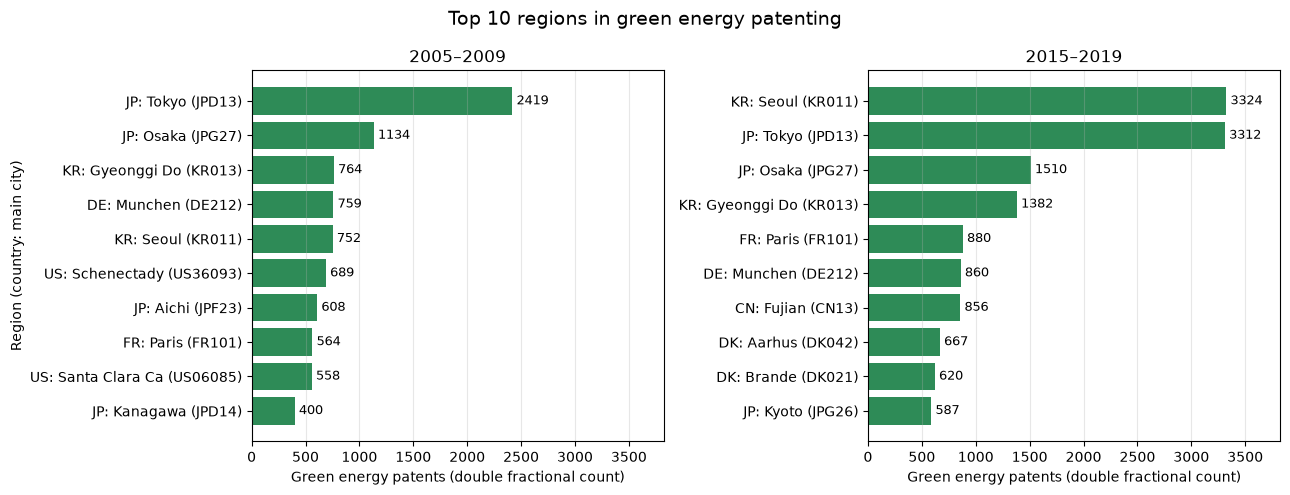

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True)
for ax, (label, top) in zip(axes, top_tables.items()):
    bars = ax.barh(top["region"], top["patents"], color="seagreen", label="Patents (double fractional count)")
    ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=9)
    ax.invert_yaxis()
    ax.set_title(label)
    ax.set_xlabel("Green energy patents (double fractional count)")
    ax.grid(axis="x", alpha=0.3)
axes[0].set_ylabel("Region (country: main city)")
axes[0].set_xlim(0, max(t["patents"].max() for t in top_tables.values()) * 1.15)
fig.suptitle("Top 10 regions in green energy patenting", fontsize=14)
fig.tight_layout()
plt.show()

## 3. Geographic concentration

For each period we compute, for green patents and for all patents:

* the number of regions with any patents,
* the share of the top 10 regions,
* the Herfindahl index $HHI = \sum_r s_r^2$, where $s_r$ is region $r$'s share of the period's patents.
  $HHI$ is 1 if all patents are in one region and close to 0 if they are spread over many regions.

In [9]:
def concentration(counts):
    shares = counts / counts.sum()
    return pd.Series(
        {
            "Regions": (counts > 0).sum(),
            "Top-10 share (%)": shares.nlargest(10).sum() * 100,
            "HHI (×1000)": (shares**2).sum() * 1000,
        }
    )


by_region = (
    regions.groupby(["period", "reg_code"], observed=True)
    .agg(all_patents=("weight", "sum"), green=("weight", lambda w: w[regions.loc[w.index, "green"]].sum()))
)

conc = pd.concat(
    {
        "Green energy": by_region["green"].groupby(level="period", observed=True).apply(concentration).unstack(),
        "All patents": by_region["all_patents"].groupby(level="period", observed=True).apply(concentration).unstack(),
    },
    axis=1,
)
conc.index.name = "Period"
conc.round(1)

Green energy                              All patents  \
               Regions Top-10 share (%) HHI (×1000)     Regions   
Period                                                            
2000–2004       1151.0             34.9        26.4      3319.0   
2005–2009       1605.0             33.1        17.6      3352.0   
2010–2014       1685.0             36.7        20.8      3328.0   
2015–2019       1588.0             37.0        23.2      3336.0   

                                        
          Top-10 share (%) HHI (×1000)  
Period                                  
2000–2004             27.1        14.9  
2005–2009             24.7        12.5  
2010–2014             25.8        12.4  
2015–2019             25.3        11.4

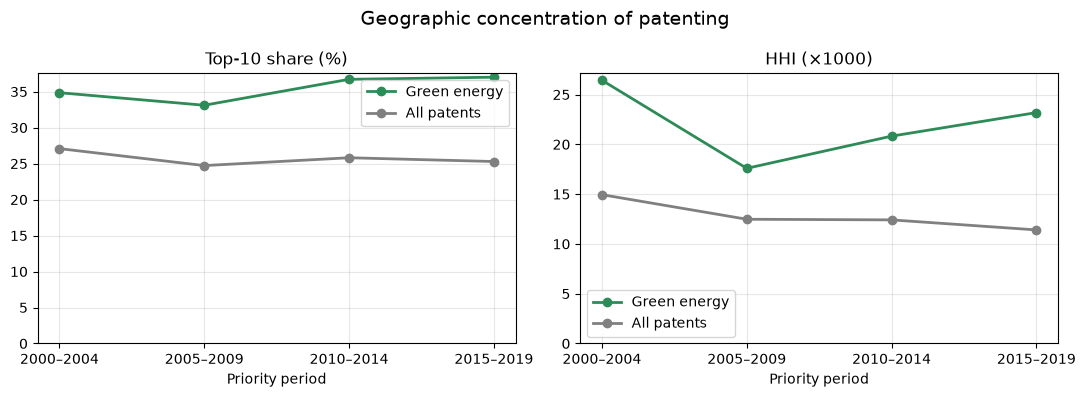

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, measure in zip(axes, ["Top-10 share (%)", "HHI (×1000)"]):
    for group, color in [("Green energy", "seagreen"), ("All patents", "grey")]:
        ax.plot(conc.index.astype(str), conc[(group, measure)], marker="o", color=color, lw=2, label=group)
    ax.set_title(measure)
    ax.set_xlabel("Priority period")
    ax.set_ylim(0)
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle("Geographic concentration of patenting", fontsize=14)
fig.tight_layout()
plt.show()

## 4. The slump in the leading regions

In [11]:
green_regions = by_region["green"].unstack("period")
lead = green_regions["2010–2014"].nlargest(10).index

slump = green_regions.loc[lead, ["2010–2014", "2015–2019"]]
slump.loc["Top 10 together"] = slump.sum()
slump.loc["All regions"] = green_regions[["2010–2014", "2015–2019"]].sum()
slump["Change (%)"] = (slump["2015–2019"] / slump["2010–2014"] - 1) * 100
slump.insert(0, "Region", region_label.reindex(slump.index).fillna(""))
slump.columns.name = None
slump.round(1)

,Region,2010–2014,2015–2019,Change (%)
reg_code,,,,
JPD13,JP: Tokyo (JPD13),3711.9,3312.0,-10.8
KR011,KR: Seoul (KR011),1700.2,3324.0,95.5
DE212,DE: Munchen (DE212),1656.1,860.4,-48.0
JPG27,JP: Osaka (JPG27),1418.8,1510.4,6.5
KR013,KR: Gyeonggi Do (KR013),1303.8,1381.7,6.0
FR101,FR: Paris (FR101),994.7,880.2,-11.5
JPD14,JP: Kanagawa (JPD14),829.5,529.9,-36.1
JPF23,JP: Aichi (JPF23),791.4,515.4,-34.9
US36093,US: Schenectady (US36093),750.5,482.3,-35.7



## Answers to Task 6

**1. Double fractional counting works.** Both checkpoints from the term paper match. With the weight
`app_share × reg_share`, the weights of 99.9995% of the patents add up to 1. The sum of all weights (2,835,175) is
almost exactly the number of patents with applicant data (2,835,170). The few exceptions are patents with a
`reg_share` of 2 in the raw data, which is a data error and too small to matter. Exact duplicate rows are dropped
first; otherwise a few applicants would be counted twice in the same region.

**2. Top regions.** Green energy innovation is concentrated in a few large industrial regions in East Asia and Europe:

* In **2005–2009**, **Tokyo** was far ahead (2,419 patents), followed by Osaka (1,134), Gyeonggi-do (764),
  Munich (759) and Seoul (752). Two US regions are on the list: Schenectady (689), where General Electric's energy
  business is based, and Santa Clara County / Silicon Valley (558).
* In **2015–2019**, **Seoul** (3,324) has caught up with Tokyo (3,312). Korea and Japan hold the four largest regions.
  The US regions have dropped out of the top 10. New on the list are **Fujian** in China (857) and two Danish regions,
  **Aarhus** and **Brande**. These are the home regions of wind turbine makers, which fits the wind recovery found in
  Task 4.

**3. Concentration.** Green energy patenting is **more concentrated** than patenting in general. The top 10 regions
hold 33–37% of green patents but only 25–27% of all patents. The HHI for green patents is about 1.5–2 times higher
(17.6–26.4 against 11.4–14.9). The difference has grown since 2005–2009. Green concentration rose from 33.1% to 37.0%
(HHI 17.6 → 23.2), while patenting in general became slightly *less* concentrated. Green innovation spread to more
regions during the boom (1,151 → 1,685 regions) and then gathered in the leading regions again.

**4. The slump in the leading regions.** The slump did not hit all leading regions equally. Measured in five-year
periods, total green patenting was flat from 2010–2014 to 2015–2019 (+0.5%), and the top 10 regions of 2010–2014 fell
by 3.7% together. Behind that small change, the regions moved very differently:

* **Seoul nearly doubled** (+95.5%), and Osaka and Gyeonggi-do grew by about 6%.
* **Munich halved** (−48.0%). Kanagawa, Aichi, Schenectady and Stuttgart fell by 23–36%, and Tokyo and Paris by
  about 11%.

So the slump hit regions specialised in the technologies that collapsed in Tasks 3–4, such as solar and efficient
combustion: German and US industrial regions and several Japanese ones. Korean regions grew strongly, which fits the
growth in **storage (batteries)** from Task 3.
